# M2 CatBoost Feature Selection and Tuning on IEEE-CIS

## 1. Introduction
In notebook 05, M2 CatBoost (retrained every 7 days on all earlier days, with the 7-day label delay) is the best model so far, with a validation PR-AUC of 0.653. It is far ahead of M2 LGBM (0.619), M2 RF (0.562) and M2 LR (0.511) **BUT** it still uses the M0 settings (depth 6, 500 trees, learning rate 0.1) and all 575 candidate features => this notebook selects the features and tunes the settings for the model

We only tune CatBoost since it is far ahead in M2 (about 0.034 above LGBM, 0.09 above RF and 0,14 above LR) => tuning LGBM, RF, or LR is unlikely to close this gap

The notebook covers:
- **Tuning blocks** (Section 3): we repeat the M2 retraining on the training days, so every choice is made without the validation rows

- **Feature selection** (Section 4): we remove the correlated `V` and `C` / `D` columns from notebook 04, look at the importance and SHAP values of the remaining features, and remove the features that barely change PR-AUC on the days after the model’s training data when they are shuffled (permutation importance)

- **Tuning with Optuna** (Section 5): Optuna tries one setting at a time and uses the results of the earlier trials to choose the next trial, so it needs fewer trials than a full grid. M2 retrains every 7 days, so each trial trains one CatBoost model for each of the 5 tuning blocks in Section 3 (so each trial could take very long to run)

- **Validation** (Section 6): we rerun M2 on the validation rows with the selected features and the tuned settings, and compare with M2 CatBoost from notebook 05

The features come from `04_feature_engineering.ipynb` (saved in `data/processed/`). We only use the training and validation rows here. The test rows are kept aside for the final evaluation, which is run once after all choices are fixed

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import optuna

from catboost import CatBoostClassifier, Pool
from sklearn.metrics import average_precision_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
optuna.logging.set_verbosity(optuna.logging.WARNING)

SEED = 100
PROCESSED_DIR = Path("../data/processed")

# everything this notebook trains is saved here, so a rerun loads the finished runs instead of training them again
RUNS_DIR = Path("../data/interim/m2_tuning")
RUNS_DIR.mkdir(parents=True, exist_ok=True)

/Users/lycia/venv-notebook/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Data Loading and Preparation
We load the features the same way as notebook 05 (Section 2.2):
- missing values in categorical columns are replaced with the text `"missing"`, and these columns are stored as pandas categories

- `card1`, `card2`, `card3`, `card5`, `addr1` and `addr2` are codes, so we turn them into text categories e.g. 315.0 becomes `"315"`

- numeric columns are stored as float32

The training and validation rows are kept in one frame (`X`, `y`) with the day of each row, since M2 also trains on the validation rows that are already labelled

In [2]:
features = pd.read_pickle(PROCESSED_DIR / "ieee_features.pkl")
with open(PROCESSED_DIR / "feature_lists.json") as f:
    feature_lists = json.load(f)

# these columns are stored as numbers, but the numbers are codes with no order
CODE_AS_CATEGORY = ["card1", "card2", "card3", "card5", "addr1", "addr2"]

feature_cols = feature_lists["ieee_feature_cols"]
cat_cols = []
num_cols = []
for col in feature_cols:
    if col in feature_lists["ieee_categorical_cols"] or col in CODE_AS_CATEGORY:
        cat_cols.append(col)
    else:
        num_cols.append(col)
v_drop = feature_lists["ieee_v_reduced_drop"]
cd_drop = feature_lists["ieee_cd_corr_drop"]

# keep only the needed columns, and only the training and validation rows
keep = feature_cols + ["isFraud", "ieee_split", "TransactionDT"]
features = features.loc[features["ieee_split"].isin(["train", "validation"]), keep]
features[num_cols] = features[num_cols].astype("float32")
for col in cat_cols:
    if col in CODE_AS_CATEGORY:
        # numbers to text codes e.g. 315.0 becomes "315" and a missing value becomes "missing"
        numbers = pd.to_numeric(features[col], errors="coerce")
        values = numbers.to_numpy(dtype="float64")
        rounded = np.round(values)
        whole = np.isfinite(values) & np.isclose(values, rounded)
        text = np.full(len(features), "missing", dtype=object)
        text[whole] = rounded[whole].astype("int64").astype(str)
        other = np.isfinite(values) & ~whole   # not a whole number => keep the value
        text[other] = numbers.to_numpy(dtype=object)[other]
        features[col] = pd.Series(text, index=features.index).astype("category")
    else:
        features[col] = features[col].astype("object").fillna("missing").astype(str).astype("category")

X, y = features[feature_cols], features["isFraud"]
day = (features["TransactionDT"] // 86400).to_numpy()
is_train = (features["ieee_split"] == "train").to_numpy()
is_val = ~is_train
del features

print("training rows:", is_train.sum(), ", days", day[is_train].min(), "to", day[is_train].max(), "| fraud rate:", round(y[is_train].mean() * 100, 2), "%")
print("validation rows:", is_val.sum(), ", days", day[is_val].min(), "to", day[is_val].max(), "| fraud rate:", round(y[is_val].mean() * 100, 2), "%")
print("features:", len(feature_cols), "\ncategorical (with the 6 code columns):", len(cat_cols), "\nV drop list:", len(v_drop), "\nC / D drop list:", len(cd_drop))

training rows: 377945 , days 1 to 109 | fraud rate: 3.41 %
validation rows: 94487 , days 109 to 141 | fraud rate: 3.92 %
features: 575 
categorical (with the 6 code columns): 47 
V drop list: 221 
C / D drop list: 6


### 2.1 Encodings
Same as notebook 05 (Section 9.1): the 16 frequency features and the 8 `card1` statistics are refitted before every retrain on all rows before the block start, so a model never uses encodings that know later days. They do not use the labels, so the label delay does not apply to them

In [3]:
# the frequency and card1 statistic features from notebook 04, which are fitted there once on all training rows
FREQ_SOURCE_COLS = []
for col in feature_cols:
    if col.endswith("_freq"):
        FREQ_SOURCE_COLS.append(col.removesuffix("_freq"))
CARD1_STAT_SOURCE_COLS = ["TransactionAmt", "D1", "D10", "D15"]

# count of each value and the card1 statistics, learned from encode_rows only (no labels are used)
def fit_encodings(encode_rows):
    X_enc = X.loc[encode_rows, FREQ_SOURCE_COLS + CARD1_STAT_SOURCE_COLS]
    counts = {}
    for col in FREQ_SOURCE_COLS:
        counts[col] = X_enc[col].value_counts()

    # float64 so the averages are the same as in notebook 04
    stats = {}
    for col in CARD1_STAT_SOURCE_COLS:
        stats[col] = X_enc[col].astype("float64").groupby(X_enc["card1"], observed=True).agg(["mean", "std"])
    return counts, stats

# replace the encoded columns of X_part (a value not in encode_rows gets a count of 0 and no statistics, as in notebook 04)
def apply_encodings(X_part, encodings):
    counts, stats = encodings
    for col in FREQ_SOURCE_COLS:
        X_part[f"{col}_freq"] = X_part[col].map(counts[col]).astype("float32").fillna(0)
    for col in CARD1_STAT_SOURCE_COLS:
        for stat in ["mean", "std"]:
            X_part[f"{col}_{stat}_by_card1"] = X_part["card1"].map(stats[col][stat]).astype("float32")
    return X_part

### 2.2 Feature Groups
The same groups as notebook 05 (Section 6.1). They are used to read the importance and SHAP results by group (Section 4.2)

In [4]:
v_cols = []
for col in feature_cols:
    if col.startswith("V") and col[1:].isdigit():
        v_cols.append(col)
v_missing = X.loc[is_train, v_cols].isna().mean().round(2)

window_cols = {"is_first_txn", "amt_to_prior_mean", "amt_prior_zscore", "is_new_category"}
missing_cols = {"missing_count", "missing_fraction", "card_missing_count", "address_missing_count", "D_nonmissing_count", "D_zero_count"}
device_cols = {"DeviceType", "DeviceInfo", "device_brand", "id30_os_family", "id31_browser_family", "os_browser_pair", "has_identity",
               "screen_width", "screen_height", "screen_pixels"}
time_cols = {"hour", "minute", "seconds_in_day", "is_night", "hour_sin", "hour_cos", "day_sin", "day_cos"}

CARD_HISTORY_GROUPS = {"card window", "card past averages", "card history"}

group_of = {}
for col in feature_cols:
    if col in v_missing.index:
        group_of[col] = f"V (missing {v_missing[col]:.0%})"
    elif col in CODE_AS_CATEGORY:
        group_of[col] = "card and address codes"
    elif col.endswith("_by_card1"):
        group_of[col] = "coarse group statistics"
    elif col.endswith(("_card_past_mean", "_card_past_std", "_card_past_distinct", "_new_for_card")):
        group_of[col] = "card past averages"
    elif col.startswith(("txn_count_", "amt_sum_", "amt_mean_")) or col in window_cols:
        group_of[col] = "card window"
    elif col in {"card_id_previous_count", "card_id_seconds_since_previous"} or col.startswith(("D3_gap", "D3_matches")):
        group_of[col] = "card history"
    elif col.endswith(("_previous_count", "_seconds_since_previous")):
        group_of[col] = "coarse key history"
    elif col.endswith("_freq"):
        group_of[col] = "frequency"
    elif col in missing_cols or col.endswith(("missing_count", "missing_fraction", "_missing")):
        group_of[col] = "missingness"
    elif col.startswith("C") and col[1:].isdigit():
        group_of[col] = "C"
    elif (col.startswith("D") and col[1:].isdigit()) or col == "D3_log1p":
        group_of[col] = "D"
    elif col.startswith("M") and col[1:].isdigit():
        group_of[col] = "M"
    elif col.startswith("id_"):
        group_of[col] = "identity id_"
    elif col in device_cols or col.startswith("deviceinfo_"):
        group_of[col] = "device"
    elif "emaildomain" in col or col == "email_domain_match":
        group_of[col] = "email"
    elif col.startswith("card"):
        group_of[col] = "card"
    elif col.startswith(("addr", "dist", "address")):
        group_of[col] = "address"
    elif col.startswith(("TransactionAmt", "amount")):
        group_of[col] = "amount"
    elif col in time_cols:
        group_of[col] = "time"
    elif col == "ProductCD":
        group_of[col] = "product"
    else:
        group_of[col] = "other"

print("features per group:")
display(pd.Series(group_of).value_counts().rename("features").to_frame().T)

features per group:


,V (missing 0%),V (missing 74%),V (missing 83%),V (missing 75%),V (missing 16%),identity id_,card past averages,missingness,V (missing 18%),V (missing 31%),D,V (missing 73%),frequency,card window,C,device,V (missing 57%),coarse key history,M,time,coarse group statistics,email,card and address codes,amount,card history,card,address,product
features,86,50,47,46,45,38,37,21,20,18,16,16,16,16,14,14,11,10,9,8,8,7,6,5,4,3,3,1


## 3. Tuning Blocks
To make every choice without the validation rows, we repeat the M2 retraining on the training days, exactly as in the notebook 05 simulation (Section 9.2). For a block that starts on day `d`:
- the model trains on all labelled training rows before day `d - 7` (7-day label delay, all earlier days)

- the encodings are refitted on all training rows before day `d`

- the model scores days `d` to `d + 6`

We use the same 5 blocks as Section 9.2, which start on days 81, 88, 95, 102 and 109, so together they score days 81 to 109 (Note: we split the data by number of rows, not by whole days, so day 109 is partly in train and partly in validation, and day 141 is partly in validation and partly in test. Each row is only in one split so there is no leakage)

Every choice below uses the **pooled PR-AUC**: the scores of all 5 blocks are put together and one PR-AUC is computed over all scored rows, same as Section 9.2 and the validation results of notebook 05. Each block has its own model, so pooling also checks that the scores of the different models are comparable with each other

Note: with the notebook 05 settings and all features, the first run in Section 4 should give the Section 9.2 result for CatBoost (0.5526) => this checks that the setup is the same as notebook 05

In [5]:
LABEL_DELAY_DAYS = 7
FREQUENCY = 7
BLOCK_STARTS = [81, 88, 95, 102, 109]

# rows of each tuning block: the rows it trains on, the rows it scores and the rows its encodings are fitted on
blocks = []
rows = []
for block_start in BLOCK_STARTS:
    fit_rows = is_train & (day < block_start - LABEL_DELAY_DAYS)
    score_rows = is_train & (day >= block_start) & (day < block_start + FREQUENCY)
    encode_rows = is_train & (day < block_start)
    blocks.append((fit_rows, score_rows, encode_rows))
    rows.append({"block start": block_start, "trained on days": f"{day[fit_rows].min()}-{day[fit_rows].max()}",
                 "scored days": f"{block_start}-{block_start + FREQUENCY - 1}", "training rows": int(fit_rows.sum()),
                 "scored rows": int(score_rows.sum()), "fraud rate in scored rows": round(y[score_rows].mean(), 4)})
display(pd.DataFrame(rows).set_index("block start"))

# labels of all scored rows, in the same order as the pooled scores
y_scored = []
for fit_rows, score_rows, encode_rows in blocks:
    y_scored.append(y[score_rows].to_numpy())
y_scored = np.concatenate(y_scored)

# M2 CatBoost settings from notebook 05
M2_SETTINGS = {"depth": 6, "iterations": 500, "learning_rate": 0.1}


# train one model per tuning block on cols and score the block's days
# returns the pooled PR-AUC over all scored rows, the PR-AUC of each block and (if asked) the models and scored rows
def block_runs(settings, cols, keep_models=False, trial=None):
    labels = []
    scores = []
    pr_aucs = []
    block_models = []

    cat_features = []
    for col in cat_cols:
        if col in cols:
            cat_features.append(col)

    for i, (fit_rows, score_rows, encode_rows) in enumerate(blocks):
        encodings = fit_encodings(encode_rows)
        X_fit = apply_encodings(X[fit_rows], encodings)[cols]
        X_score = apply_encodings(X[score_rows], encodings)[cols]
        model = CatBoostClassifier(random_seed=SEED, thread_count=-1, verbose=0, allow_writing_files=False, **settings)
        model.fit(X_fit, y[fit_rows], cat_features=cat_features)
        block_scores = model.predict_proba(X_score)[:, 1]
        labels.append(y[score_rows].to_numpy())
        scores.append(block_scores)
        pr_aucs.append(average_precision_score(y[score_rows], block_scores))
        if keep_models:
            block_models.append((model, X_score))
        del X_fit

        # Optuna: report the pooled PR-AUC of the blocks so far, and stop the trial early if it is much worse than the earlier trials
        if trial is not None:
            trial.report(average_precision_score(np.concatenate(labels), np.concatenate(scores)), i)
            if trial.should_prune():
                raise optuna.TrialPruned()

    pooled = average_precision_score(np.concatenate(labels), np.concatenate(scores))
    return pooled, pr_aucs, block_models


,trained on days,scored days,training rows,scored rows,fraud rate in scored rows
block start,,,,,
81,1-73,81-87,264730,20901,0.0387
88,1-80,88-94,285426,27314,0.0322
95,1-87,95-101,306327,22575,0.0345
102,1-94,102-108,333641,20733,0.0396
109,1-101,109-115,356216,996,0.0361


## 4. Feature Selection
We start from all 575 features with the M2 settings from notebook 05, and select the features in 4 steps:
1. **Correlated columns** (Section 4.1): we remove the columns on the correlation drop lists from notebook 04 directly, since a column we keep carries similar information. This also makes the importance easier to read, since correlated features share their importance

2. **Feature Importance (LossFunctionChange) and SHAP** (Section 4.2): we train the 5 block models on the remaining columns and look at every feature

3. **Permutation importance** (Section 4.3): we shuffle one feature at a time and plot how much PR-AUC drops, to see where the drop flattens out

4. **Removing features** (Section 4.4): we remove the features past that point, and check with one retrain that PR-AUC does not fall

We look at single features instead of removing whole groups, since a group score can hide features that help next to features that hurt. In notebook 05 (Section 9.6) removing all 57 card-history features together did not lower the validation PR-AUC of M2 CatBoost **BUT** this does not show that none of them help (in facr, some of them are retained after our feature selection, see Section 4.4)

In [6]:
TOLERANCE = 0.002


# pooled and block PR-AUCs with the M2 settings, saved so a rerun does not train them again
def selection_run(name, cols):
    path = RUNS_DIR / f"selection_{name}.json"
    if path.exists():
        return json.loads(path.read_text())
    start = time.time()
    pooled, pr_aucs, _ = block_runs(M2_SETTINGS, cols)
    result = {"PR-AUC": pooled, "PR-AUC per block": pr_aucs}
    path.write_text(json.dumps(result))
    print(f"{name}: {len(cols)} features ({time.time() - start:.0f}s)")
    return result


selection = []
all_run = selection_run("all_features", feature_cols)
base_score = all_run["PR-AUC"]
print(f"all features with the notebook 05 settings: {base_score:.4f} (notebook 05, Section 9.2: 0.5526)")
selection.append({"step": "all features", "features": len(feature_cols), "PR-AUC": base_score, "PR-AUC per block": all_run["PR-AUC per block"], "removed": "-"})

all features with the notebook 05 settings: 0.5526 (notebook 05, Section 9.2: 0.5526)


### 4.1 Correlated Columns
We remove 2 drop lists from notebook 04:
- **`V` drop list**: `V` columns with an absolute Spearman correlation above 0.75 with another `V` column that is missing in the same training rows (221 columns)

- **`C` / `D` drop list**: `C` and `D` columns with an absolute Spearman correlation above 0.9 with another `C` or `D` column (6 columns)

In [7]:
selected_cols = []
for col in feature_cols:
    if col not in v_drop and col not in cd_drop:
        selected_cols.append(col)
print("features after removing the correlated columns:", len(selected_cols))

selected_groups = []
for col in selected_cols:
    selected_groups.append(group_of[col])
display(pd.Series(selected_groups).value_counts().rename("features").to_frame().T)

features after removing the correlated columns: 348


,identity id_,V (missing 0%),card past averages,missingness,V (missing 16%),V (missing 75%),frequency,card window,device,C,V (missing 74%),D,V (missing 83%),coarse key history,M,V (missing 18%),time,coarse group statistics,email,V (missing 31%),card and address codes,V (missing 57%),amount,V (missing 73%),card history,card,address,product
features,38,37,37,21,16,16,16,16,14,13,13,11,11,10,9,8,8,8,7,7,6,6,5,4,4,3,3,1


### 4.2 Feature Importance (LossFunctionChange) and SHAP
We train the 5 block models on the columns from Section 4.1 with the notebook 05 settings, and compute 2 measures for every feature, averaged over the 5 blocks:
- **`LossFunctionChange`**: how much the log loss on the block's scored days gets worse without the feature
    - Above 0, the feature helps on later days
    - At 0 or below, it does not

- **Mean |SHAP|**: how much the feature moves the scores, on 5,000 scored rows per block (same as notebook 05, Section 8) => this shows what the model relies on **BUT** not whether that helps on later days

Note: the drop lists only remove some of the correlated columns (e.g. TransactionAmt and TransactionAmt_log1p are both still in), and correlated features share credit, so a low value does not prove that a feature is useless

all features 0.5526 | without the correlated columns 0.5530 (348 features)
features with loss change above 0: 191 of 348


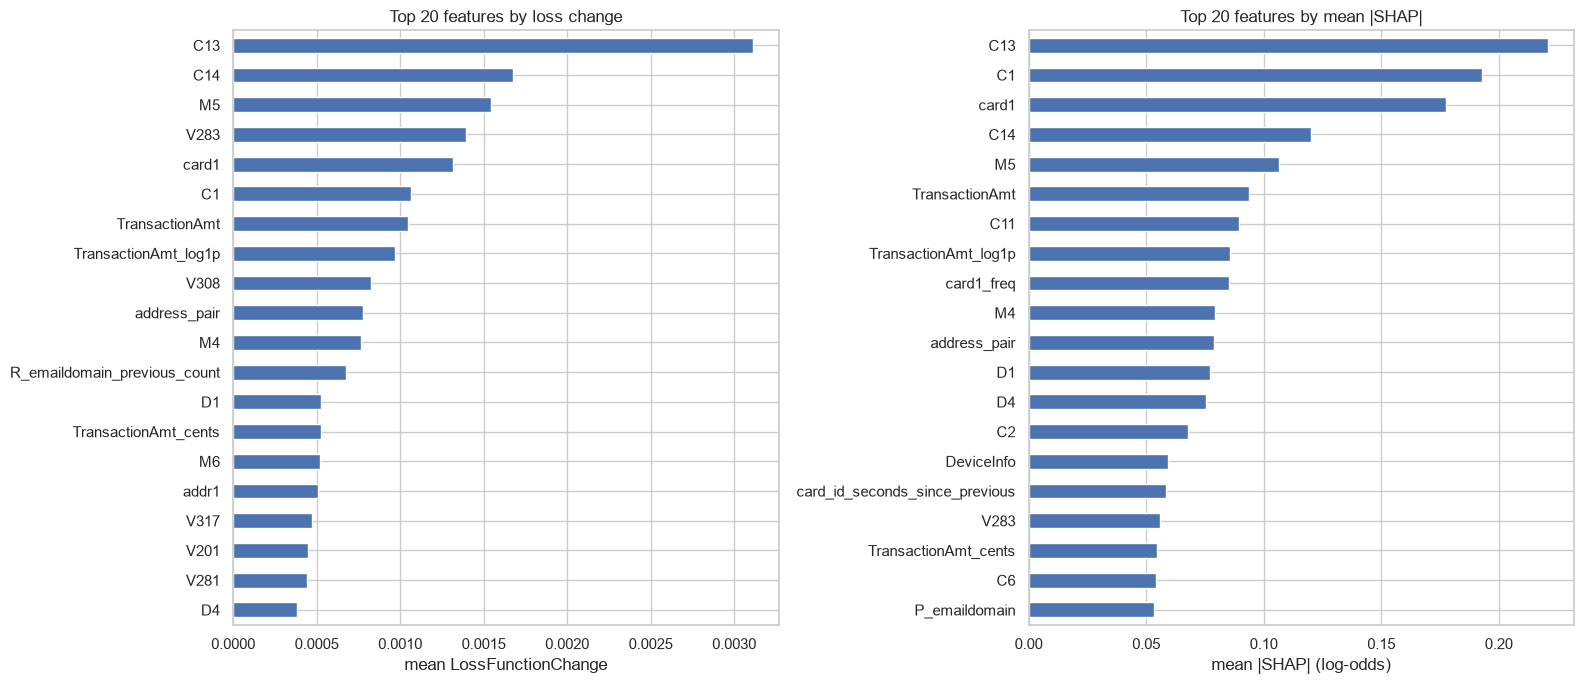

,features,above_0,loss_change,shap
group,,,,
C,13,10,0.00642,0.82918
V (missing 0%),37,24,0.00445,0.27345
M,9,7,0.00286,0.28597
amount,5,5,0.00285,0.26341
card and address codes,6,3,0.00167,0.27762
coarse key history,10,8,0.00160,0.20840
D,11,9,0.00147,0.26860
address,3,3,0.00088,0.08975
V (missing 16%),16,11,0.00057,0.11378


In [8]:
importance_path = RUNS_DIR / f"feature_importance_{len(selected_cols)}.pkl"
correlated_path = RUNS_DIR / f"selection_no_correlated_{len(selected_cols)}.json"

if importance_path.exists() and correlated_path.exists():
    importance = pd.read_pickle(importance_path)
    correlated_run = json.loads(correlated_path.read_text())
else:
    start = time.time()
    pooled, pr_aucs, block_models = block_runs(M2_SETTINGS, selected_cols, keep_models=True)
    correlated_run = {"PR-AUC": pooled, "PR-AUC per block": pr_aucs}
    correlated_path.write_text(json.dumps(correlated_run))

    cat_features = []
    for col in cat_cols:
        if col in selected_cols:
            cat_features.append(col)

    loss_changes = []
    mean_shaps = []
    for i in range(len(blocks)):
        model, X_score = block_models[i]
        fit_rows, score_rows, encode_rows = blocks[i]

        score_pool = Pool(X_score, y[score_rows], cat_features=cat_features)
        loss_changes.append(model.get_feature_importance(score_pool, type="LossFunctionChange"))

        # the last column is the bias term, so we drop it
        shap_rows = X_score.sample(min(5000, len(X_score)), random_state=SEED)
        shap_pool = Pool(shap_rows, cat_features=cat_features)
        shap_values = model.get_feature_importance(shap_pool, type="ShapValues")[:, :-1]
        mean_shaps.append(np.abs(shap_values).mean(axis=0))

    groups = []
    for col in selected_cols:
        groups.append(group_of[col])

    importance = pd.DataFrame(index=selected_cols)
    importance["group"] = groups
    importance["loss change"] = np.mean(loss_changes, axis=0)
    importance["blocks above 0"] = (np.array(loss_changes) > 0).sum(axis=0)
    importance["mean |SHAP|"] = np.mean(mean_shaps, axis=0)
    importance = importance.sort_values("loss change", ascending=False)
    importance.to_pickle(importance_path)
    del block_models
    print(f"importance and SHAP ({time.time() - start:.0f}s)")

print(f"all features {base_score:.4f} | without the correlated columns {correlated_run['PR-AUC']:.4f} ({len(selected_cols)} features)")
print("features with loss change above 0:", (importance["loss change"] > 0).sum(), "of", len(importance))

# top 20 features by each measure
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
importance["loss change"].head(20).iloc[::-1].plot.barh(ax=axes[0])
axes[0].set_title("Top 20 features by loss change")
axes[0].set_xlabel("mean LossFunctionChange")
importance["mean |SHAP|"].sort_values(ascending=False).head(20).iloc[::-1].plot.barh(ax=axes[1])
axes[1].set_title("Top 20 features by mean |SHAP|")
axes[1].set_xlabel("mean |SHAP| (log-odds)")
plt.tight_layout()
plt.show()

# the same measures per group
group_rows = []
for group, group_table in importance.groupby("group"):
    group_rows.append({"group": group, "features": len(group_table), "above_0": (group_table["loss change"] > 0).sum(),
                       "loss_change": group_table["loss change"].sum(), "shap": group_table["mean |SHAP|"].sum()})
by_group = pd.DataFrame(group_rows).set_index("group")
display(by_group.sort_values("loss_change", ascending=False).round(5))

In [9]:
# the features inside the card-history groups
print("card-history features:")
display(importance[importance["group"].isin(CARD_HISTORY_GROUPS)].round(5))

card-history features:


,group,loss change,blocks above 0,mean |SHAP|
M5_card_past_mean,card past averages,0.00020,5,0.01544
amt_sum_24h,card window,0.00011,4,0.01605
TransactionAmt_card_past_std,card past averages,0.00010,5,0.00736
D3_matches_previous_gap,card history,0.00009,2,0.01175
amt_mean_30D,card window,0.00008,3,0.01504
D15_card_past_std,card past averages,0.00005,4,0.01256
C14_card_past_std,card past averages,0.00005,4,0.00868
D3_gap_difference,card history,0.00005,4,0.01125
C6_card_past_mean,card past averages,0.00004,3,0.00777
M6_card_past_mean,card past averages,0.00003,3,0.01516


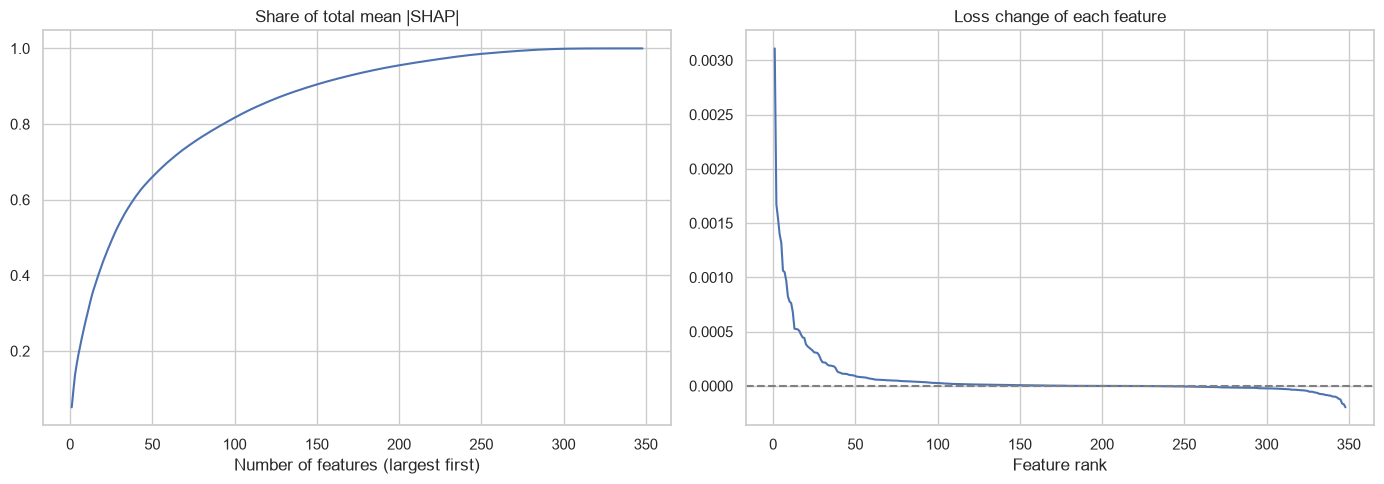

90% of total SHAP: 147 features
95% of total SHAP: 194 features
99% of total SHAP: 263 features
loss change above 0: 191 features


In [10]:
# importance is already sorted by loss change
by_shap = importance["mean |SHAP|"].sort_values(ascending=False)
cumulative_shap = by_shap.cumsum() / by_shap.sum()
ranks = range(1, len(importance) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(ranks, cumulative_shap.to_numpy())
axes[0].set_title("Share of total mean |SHAP|")
axes[0].set_xlabel("Number of features (largest first)")
axes[1].plot(ranks, importance["loss change"].to_numpy())
axes[1].axhline(0, color="grey", linestyle="--")
axes[1].set_title("Loss change of each feature")
axes[1].set_xlabel("Feature rank")
plt.tight_layout()
plt.show()

for share in [0.90, 0.95, 0.99]:
    print(f"{share:.0%} of total SHAP:", (cumulative_shap < share).sum() + 1, "features")
print("loss change above 0:", (importance["loss change"] > 0).sum(), "features")

**Takeaway: Feature Importance (LossFunctionChange) and SHAP**
- Removing the 227 correlated columns did not lower PR-AUC: 0.5530 with 348 features vs 0.5526 with all 575 features. This change is well within seed noise, so we do not take it as a gain

- Both measures put the same features at the top, and the `C` group is the largest on both (loss change 0.0064, sum of mean |SHAP| 0.83)
    - By loss change: `C13` (0.0031), `C14` (0.0017), `M5` (0.0015), `V283` (0.0014) and `card1` (0.0013)
    - By mean |SHAP|: `C13` (0.221), `C1` (0.193), `card1` (0.178), `C14` (0.120) and `M5` (0.107)

- 191 of the 348 features have a loss change above 0 => the other 157 do not lower the log loss on later days, even though the model can use them

- The model can use a feature a lot without that feature making its predictions better on later days e.g. the `frequency` features have a total mean |SHAP| of 0.22, so the model uses them a lot **BUT** their total loss change is about 0. It is the same for the `coarse group statistics` (0.18 and -0.0002) => we cannot choose the features using SHAP alone

- SHAP has no clear turning point: 147 features make up 90% of the total, 194 make up 95% and 263 make up 99%

### 4.3 Permutation Importance
`LossFunctionChange` and SHAP do not use PR-AUC, so we also measure each feature on PR-AUC directly. We shuffle one feature on each block's scored days, score them again with the block models and measure how much the pooled PR-AUC drops (repeated 3 times, then we take the mean drop)

We sort the features by this drop and plot it, to see the point where the drop flattens out. Features past this point barely change PR-AUC

Note: correlated features can still cover for each other, so a small drop does not prove that a feature is useless => this is why Section 4.4 checks the removal with a retrain

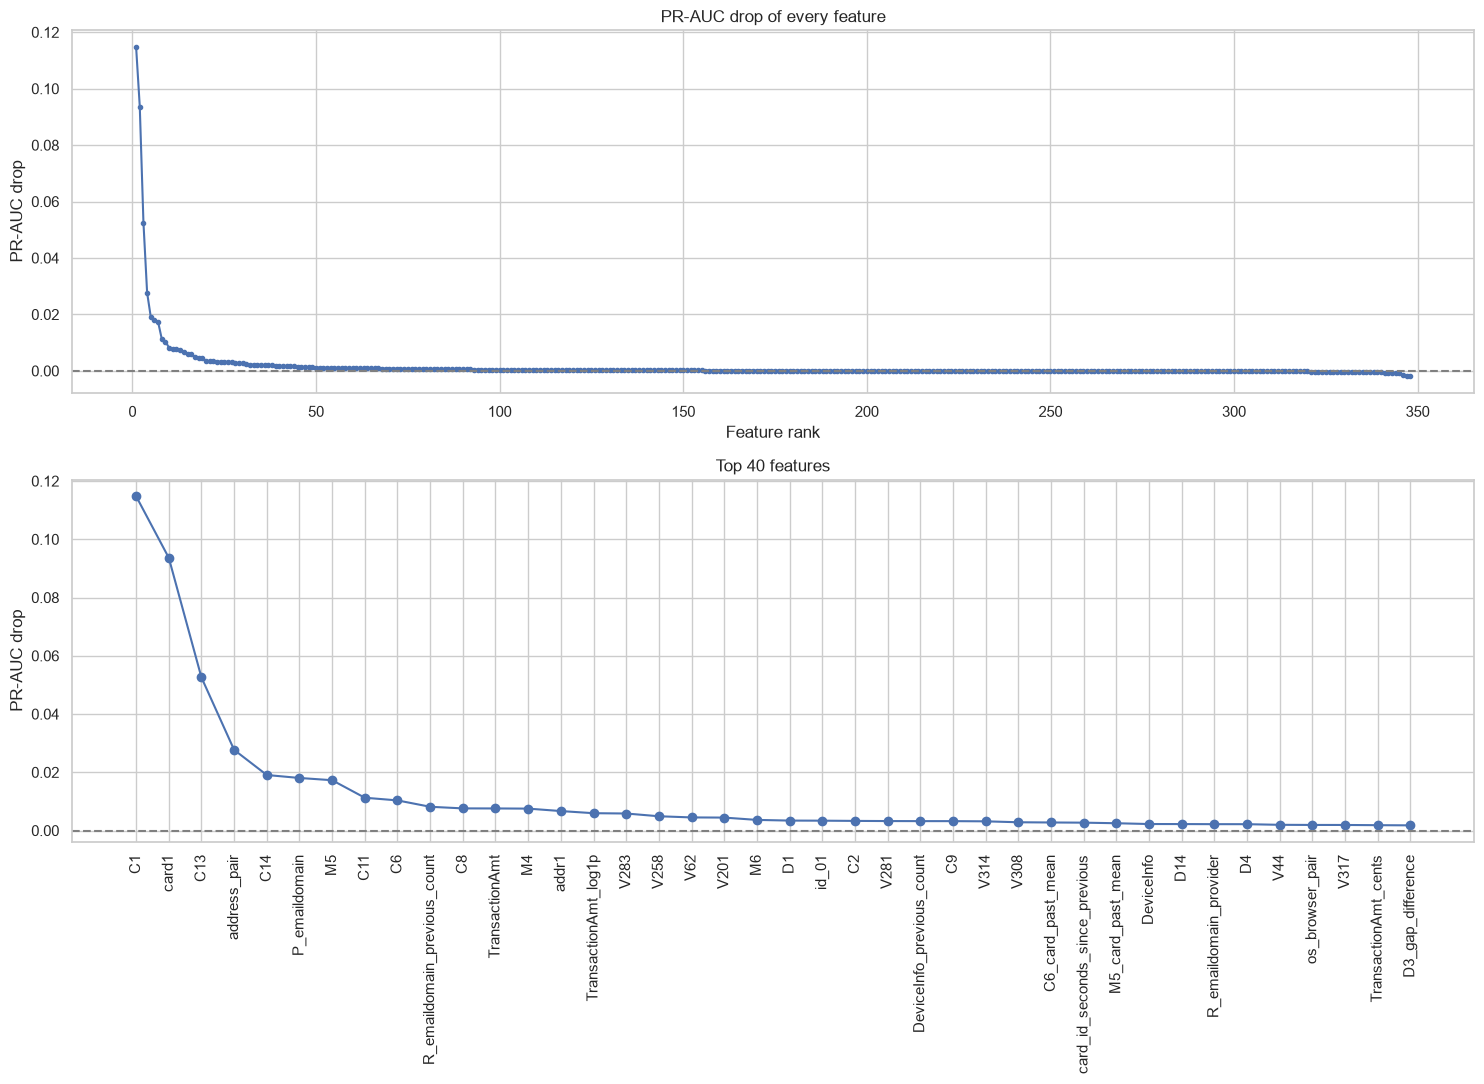

PR-AUC drop above 0.002: 35 features
PR-AUC drop above 0.001: 60 features
PR-AUC drop above 0.0005: 90 features
PR-AUC drop above 0.0002: 135 features
PR-AUC drop above 0.0001: 158 features
PR-AUC drop above 0: 209 features


,group,PR-AUC drop,drop std,loss change,mean |SHAP|
feature,,,,,
C1,C,0.11479,0.00185,0.00106,0.19287
card1,card and address codes,0.09365,0.00144,0.00132,0.17757
C13,C,0.05256,0.00127,0.00311,0.22093
address_pair,address,0.02769,0.00109,0.00078,0.07871
C14,C,0.01906,0.00080,0.00167,0.12019
P_emaildomain,email,0.01804,0.00074,0.00031,0.05329
M5,M,0.01727,0.00071,0.00154,0.10659
C11,C,0.01126,0.00039,0.00022,0.08968
C6,C,0.01034,0.00045,0.00004,0.05401


card-history features:


,group,PR-AUC drop,drop std,loss change,mean |SHAP|
feature,,,,,
C6_card_past_mean,card past averages,0.00276,0.00018,0.00004,0.00777
card_id_seconds_since_previous,card history,0.00270,0.00010,-0.00010,0.05847
M5_card_past_mean,card past averages,0.00250,0.00007,0.00020,0.01544
D3_gap_difference,card history,0.00178,0.00012,0.00005,0.01125
TransactionAmt_card_past_std,card past averages,0.00110,0.00010,0.00010,0.00736
D15_card_past_mean,card past averages,0.00088,0.00011,-0.00003,0.01304
C1_card_past_mean,card past averages,0.00085,0.00006,-0.00003,0.00998
D15_card_past_std,card past averages,0.00059,0.00015,0.00005,0.01256
D10_card_past_mean,card past averages,0.00052,0.00012,0.00001,0.01319


In [11]:
N_REPEATS = 3
permutation_path = RUNS_DIR / f"permutation_importance_{len(selected_cols)}.pkl"

if permutation_path.exists():
    permutation = pd.read_pickle(permutation_path)
else:
    start = time.time()
    _, _, block_models = block_runs(M2_SETTINGS, selected_cols, keep_models=True)
    base_scores = []
    for model, X_score in block_models:
        base_scores.append(model.predict_proba(X_score)[:, 1])
    base = average_precision_score(y_scored, np.concatenate(base_scores))
    print(f"PR-AUC of the block models: {base:.4f} (Section 4.2: {correlated_run['PR-AUC']:.4f})")

    rng = np.random.default_rng(SEED)
    rows = []
    for i, col in enumerate(selected_cols):
        drops = []
        for repeat in range(N_REPEATS):
            perm_scores = []
            for model, X_score in block_models:
                perm = rng.permutation(len(X_score))
                X_perm = X_score.copy()
                X_perm[col] = X_score[col].iloc[perm].set_axis(X_score.index)
                perm_scores.append(model.predict_proba(X_perm)[:, 1])
            drops.append(base - average_precision_score(y_scored, np.concatenate(perm_scores)))
        rows.append({"feature": col, "group": group_of[col], "PR-AUC drop": np.mean(drops), "drop std": np.std(drops)})
        if (i + 1) % 50 == 0:
            print(f"{i + 1} of {len(selected_cols)} features ({time.time() - start:.0f}s)")

    permutation = pd.DataFrame(rows).set_index("feature").sort_values("PR-AUC drop", ascending=False)
    permutation.to_pickle(permutation_path)
    del block_models
    print(f"permutation importance ({time.time() - start:.0f}s)")

# PR-AUC drop of all features, and a closer look at the top 40
top = permutation.head(40)
fig, axes = plt.subplots(2, 1, figsize=(15, 11))
axes[0].plot(range(1, len(permutation) + 1), permutation["PR-AUC drop"].to_numpy(), marker=".")
axes[0].axhline(0, color="grey", linestyle="--")
axes[0].set_title("PR-AUC drop of every feature")
axes[0].set_xlabel("Feature rank")
axes[0].set_ylabel("PR-AUC drop")
axes[1].plot(top.index, top["PR-AUC drop"], marker="o")
axes[1].axhline(0, color="grey", linestyle="--")
axes[1].set_title("Top 40 features")
axes[1].set_ylabel("PR-AUC drop")
axes[1].tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

for cutoff in [0.002, 0.001, 0.0005, 0.0002, 0.0001, 0]:
    print(f"PR-AUC drop above {cutoff}:", (permutation["PR-AUC drop"] > cutoff).sum(), "features")

# all 3 measures together
all_measures = permutation.join(importance[["loss change", "mean |SHAP|"]])
display(all_measures.head(40).round(5))
print("card-history features:")
display(all_measures[all_measures["group"].isin(CARD_HISTORY_GROUPS)].round(5))

In [ ]:
# what each possible cutoff keeps
# suppose the cut-off is 0.0003 and 15 features have a drop below -0.0003 => those must be by chance as shuffling does not really help a model
# since chances go both ways, about 15 useless features probably also have a drop above +0.0003 => so of the 115 features kept, approx 15 may be from luck
total_drop = all_measures.loc[all_measures["PR-AUC drop"] > 0, "PR-AUC drop"].sum()
total_loss = all_measures.loc[all_measures["loss change"] > 0, "loss change"].sum()
total_shap = all_measures["mean |SHAP|"].sum()

rows = []
for cutoff in [0.001, 0.0005, 0.0003, 0.0002, 0.0001, 0]:
    kept = all_measures[all_measures["PR-AUC drop"] > cutoff]
    by_luck = (all_measures["PR-AUC drop"] < -cutoff).sum()
    rows.append({"MIN_DROP": cutoff, "features kept": len(kept), "by luck (estimate)": by_luck, "share by luck": by_luck / len(kept),
                 "share of PR-AUC drop": kept["PR-AUC drop"].sum() / total_drop,
                 "share of loss change": kept.loc[kept["loss change"] > 0, "loss change"].sum() / total_loss,
                 "share of SHAP": kept["mean |SHAP|"].sum() / total_shap,
                 "card-history features": kept["group"].isin(CARD_HISTORY_GROUPS).sum()})
display(pd.DataFrame(rows).set_index("MIN_DROP").round(3))

,features kept,by luck (estimate),share by luck,share of PR-AUC drop,share of loss change,share of SHAP,card-history features
MIN_DROP,,,,,,,
0.0010,60,3,0.050,0.926,0.833,0.612,5
0.0005,90,11,0.122,0.964,0.877,0.690,9
0.0003,115,15,0.130,0.981,0.911,0.744,14
0.0002,135,34,0.252,0.990,0.923,0.778,17
0.0001,158,57,0.361,0.996,0.939,0.816,22
0.0000,209,118,0.565,1.000,0.961,0.848,28


In [18]:
# how much the 3 measures agree
print(all_measures[["PR-AUC drop", "loss change", "mean |SHAP|"]].corr(method="spearman").round(2))

drop_above_0 = all_measures["PR-AUC drop"] > 0
loss_above_0 = all_measures["loss change"] > 0
print("above 0 on both:", (drop_above_0 & loss_above_0).sum())
print("above 0 on neither:", (~drop_above_0 & ~loss_above_0).sum())

             PR-AUC drop  loss change  mean |SHAP|
PR-AUC drop         1.00         0.53         0.47
loss change         0.53         1.00         0.32
mean |SHAP|         0.47         0.32         1.00
above 0 on both: 150
above 0 on neither: 98


**Takeaway: Permutation Importance**
- A few features matter far more than the rest: shuffling `C1` lowers PR-AUC by 0.115, `card1` by 0.094 and `C13` by 0.053

- There is no sharp cliff after these: the drop is 0.008 at rank 10, 0.002 at rank 40, 0.0004 at rank 100 and about 0 at rank 200 => the plot alone does not give a cutoff, so we also need to know how large the noise is

- Many small drops could be just by luck: 118 features have a negative drop (as low as -0.0019), which means that PR-AUC went up after shuffling them. Shuffling a feature should not really help the model, so these changes are by luck => small positive drops can be by luck too

- `drop std` cannot show this: it only compares the 3 shuffles on the same models, so it is much smaller (median 0.00005)

- The 3 measures only partly agree on how the features rank: the Spearman correlation is 0.53 between the PR-AUC drop and the loss change, 0.47 between the PR-AUC drop and SHAP, and 0.32 between the loss change and SHAP (1 would mean the same order). 150 features are above 0 on both the PR-AUC drop and the loss change, and 98 are above 0 on neither

- When they disagree, we trust the PR-AUC drop the most, since PR-AUC is our main metric:
    - `C9`: shuffling it lowers PR-AUC by 0.0032 **BUT** its loss change is below 0 in all 5 blocks => it may help to rank fraud near the top even though it does not improve the log loss
    - `card1_previous_count`: the model uses it a lot (mean |SHAP| 0.049) **BUT** shuffling it does not lower PR-AUC (-0.0003) => other features (e.g. `card1`) may carry the same information, although we did not test this
    - `V62`, `V201` and `V258`: the model uses them a little (mean |SHAP| about 0.01) **BUT** shuffling each of them lowers PR-AUC by about 0.0045 => a feature can matter even if it does not move the scores much on average

### 4.4 Removing Features
We remove a feature if its mean PR-AUC drop from Section 4.3 is at or below `MIN_DROP`. We set **`MIN_DROP = 0.0003`**, which keeps 115 of the 348 features. We use the 3 measures together to choose it (see the table in Section 4.3):
- **PR-AUC drop sets the cutoff**: it is the only measure that uses PR-AUC on later days

- **The negative drops show the noise**: a useless feature is about as likely to raise PR-AUC as to lower it when shuffled, so the number of features below `-MIN_DROP` estimates how many of the features above `MIN_DROP` are only there by luck. This is about 15 of 115 (13%) at 0.0003 and about 11 of 90 (12%) at 0.0005 => going down to 0.0003 adds 25 features **BUT** only about 4 of them by luck. At 0.0002 it jumps to about 34 of 135 (25%) => 20 more features, of which about 19 by luck. So 0.0003 is the lowest cutoff before the noise jumps

- **We use loss change as a cross-check**: the 115 features keep 91% of the total positive loss change, and 93 of them have a loss change above 0. The other 22 stay because they lower PR-AUC when shuffled (e.g. `C9`). The removed features with the largest loss change are `P_emaildomain_previous_count` and `card1_previous_count` (about 0.0002 to 0.0003 each), and both have a negative PR-AUC drop

- **SHAP shows what we give up**: the 115 features keep 74% of the total mean |SHAP|, so the model does use the 233 features we remove **BUT** those 233 only make up 2% of the total positive PR-AUC drop => the model uses them without them helping much on later days, and other features may take over once they are removed. The retrain below checks that PR-AUC does not fall

`KEEP_FROM_EDA` stays empty: the EDA supports the time since the card's previous transaction (median 2.4 hours for fraud vs 49.4 hours for non-fraud, notebook 03, Section 8) and `card_id_seconds_since_previous` is already kept. 14 of the 57 card-history features are kept

Note: this is a judgement call made after looking at the results, so the retrain below and the validation rows in Section 6 are the real checks

We then retrain once without these features, and only remove them if the pooled PR-AUC stays within 0.002 of the score from Section 4.2 (0.5530 => at least 0.5510):
- 0.002 is well within seed noise (the PR-AUC range of M0 CatBoost over 3 seeds was 0.006, notebook 05 Section 5.6) => a smaller change is not evidence that the features help

Note: the features are chosen and checked on the same blocks, so this score can look more optimistic than it really is

In [13]:
# chosen from the table in Section 4.3
MIN_DROP = 0.0003

# features to keep even if their PR-AUC drop is too small, with the reason from the EDA
KEEP_FROM_EDA = []

to_remove = []
cols = []
removed_groups = []
for col in selected_cols:
    if permutation.loc[col, "PR-AUC drop"] <= MIN_DROP and col not in KEEP_FROM_EDA:
        to_remove.append(col)
        removed_groups.append(group_of[col])
    else:
        cols.append(col)
print(f"features with a PR-AUC drop of {MIN_DROP} or below:", len(to_remove))
display(pd.Series(removed_groups).value_counts().rename("removed features").to_frame().T)

selection.append({"step": "no correlated columns", "features": len(selected_cols), "PR-AUC": correlated_run["PR-AUC"], "PR-AUC per block": correlated_run["PR-AUC per block"], "removed": "yes"})
if to_remove:
    run = selection_run(f"permutation_cutoff_{len(cols)}", cols)
    remove = run["PR-AUC"] >= correlated_run["PR-AUC"] - TOLERANCE
    selection.append({"step": "no features at or below MIN_DROP", "features": len(cols), "PR-AUC": run["PR-AUC"], "PR-AUC per block": run["PR-AUC per block"], "removed": "yes" if remove else "no"})
    if remove:
        selected_cols = cols

# show the PR-AUC of each block as one line of text
for row in selection:
    block_texts = []
    for pr_auc in row["PR-AUC per block"]:
        block_texts.append(f"{pr_auc:.4f}")
    row["PR-AUC per block"] = ", ".join(block_texts)

selection_table = pd.DataFrame(selection).set_index("step")
display(selection_table.round(4))

print("selected features:", len(selected_cols))
selected_groups = []
for col in selected_cols:
    selected_groups.append(group_of[col])
display(pd.Series(selected_groups).value_counts().rename("selected features").to_frame().T)

features with a PR-AUC drop of 0.0003 or below: 233


,identity id_,card past averages,V (missing 0%),missingness,card window,frequency,V (missing 74%),V (missing 75%),V (missing 83%),device,V (missing 16%),time,V (missing 57%),V (missing 18%),D,M,coarse key history,V (missing 31%),V (missing 73%),card and address codes,coarse group statistics,card,C,card history,address,email
removed features,29,26,24,20,15,14,11,11,10,10,7,7,6,6,5,5,5,4,4,3,3,2,2,2,1,1


,features,PR-AUC,PR-AUC per block,removed
step,,,,
all features,575,0.5526,"0.5641, 0.5213, 0.4919, 0.6377, 0.4972",-
no correlated columns,348,0.5530,"0.5812, 0.5162, 0.4868, 0.6304, 0.5259",yes
no features at or below MIN_DROP,115,0.5703,"0.5911, 0.5545, 0.4985, 0.6371, 0.5135",yes


selected features: 115


,V (missing 0%),C,card past averages,V (missing 16%),identity id_,email,D,amount,V (missing 75%),coarse group statistics,coarse key history,M,device,card and address codes,V (missing 31%),address,V (missing 18%),V (missing 74%),frequency,card history,product,card,V (missing 83%),time,missingness,card window
selected features,13,11,11,9,9,6,6,5,5,5,5,4,4,3,3,2,2,2,2,2,1,1,1,1,1,1


**Takeaway: Removing Features**
- We remove the 233 features: PR-AUC is 0.5703 with the 115 selected features vs 0.5530 with 348 features and 0.5526 with all 575 features, which is above the 0.5510 needed in Section 4.4

- PR-AUC is higher in 4 of the 5 blocks compared with 348 features: +0.010, +0.038, +0.012 and +0.007 for the blocks starting on days 81, 88, 95 and 102, and -0.012 for the block starting on day 109, which only has part of day 109

- **BUT** we do not read all of this as a real gain, even though +0.017 is above the seed range of 0.006: the features were chosen on the same blocks that this score uses, so it looks more optimistic than it really is, and it is only one seed => what we can say is that removing these features did not lower PR-AUC on the tuning blocks, and the validation rows in Section 6 are the real check

- The selected features still come from most of the groups **BUT** the groups are cut by very different amounts:
    - most of `C` stays (11 of 13)
    - about half or less of `coarse key history` (5 of 10), the card and address codes (3 of 6) and the `V` columns (35 of 118) stay
    - very little of `missingness` (1 of 21), `frequency` (2 of 16) and `time` (1 of 8) stays

- 14 of the 57 card-history features stay (11 of `card past averages`, 2 of `card history`, 1 of `card window`)

- Fewer features also make each model faster: the 5 block models took about 26 minutes with 115 features vs about 59 minutes with 348 features

## 5. Tuning with Optuna
We tune these settings on the selected features:
- `depth`: 4 to 10 (depth of each tree)

- `l2_leaf_reg`: 1 to 30 (how strongly the leaf values are shrunk, larger => simpler trees)

- `random_strength`: 0.1 to 10 (random noise added when scoring the splits, larger => less overfitting)

- `bagging_temperature`: 0 to 2 (how strongly the training rows are reweighted at random for each tree, 0 => no reweighting)

- `rsm`: 0.2 to 1 (the share of features considered at each split level, smaller => faster and more random trees)

- class weights: none or `SqrtBalanced` (the square root of the balanced weights). Balanced weights lowered PR-AUC for every family in M1 (notebook 05, Section 5), so we only try the milder version

- `iterations`: 100 to 1,000 trees, in steps of 50

The learning rate stays at 0.1 (same as notebook 05). We tune the number of trees directly instead of using early stopping:
- early stopping needs labelled rows from the days being scored, which M2 does not have when it retrains

- stopping on the same days that are used to compare the trials would make the trial scores optimistic

How the search runs:
- **First trial**: the notebook 05 settings (depth 6, 500 trees, `l2_leaf_reg` 3, `random_strength` 1, `bagging_temperature` 1, all features at each level, no class weights), so we can see how much tuning adds

- **Sampler**: Optuna's default TPE sampler, which picks the next settings close to the settings that scored well so far

- **Pruning**: after each block, Optuna compares the pooled PR-AUC of the blocks so far with the other trials after the same block, and stops the trial if it is below their median (only after the first 5 trials) => a bad setting only costs 1 or 2 models instead of 5

- **Saving**: the trials are saved in `data/interim/m2_tuning/optuna.db`

In [14]:
N_TRIALS = 40


def objective(trial):
    settings = {
        "learning_rate": 0.1,
        "iterations": trial.suggest_int("iterations", 100, 1000, step=50),
        "depth": trial.suggest_int("depth", 4, 10),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1, 30, log=True),
        "random_strength": trial.suggest_float("random_strength", 0.1, 10, log=True),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0, 2),
        "rsm": trial.suggest_float("rsm", 0.2, 1.0),
    }
    class_weights = trial.suggest_categorical("class_weights", ["none", "SqrtBalanced"])
    if class_weights != "none":
        settings["auto_class_weights"] = class_weights

    start = time.time()
    try:
        pooled, pr_aucs, _ = block_runs(settings, selected_cols, trial=trial)
    except optuna.TrialPruned:
        print(f"trial {trial.number}: pruned ({time.time() - start:.0f}s)")
        raise
    trial.set_user_attr("PR-AUC per block", pr_aucs)
    print(f"trial {trial.number}: PR-AUC {pooled:.4f} ({time.time() - start:.0f}s)")
    return float(pooled)


# the study name includes the number of features, so a different feature selection starts a new study
study = optuna.create_study(study_name=f"m2_catboost_{len(selected_cols)}_features", storage=f"sqlite:///{RUNS_DIR / 'optuna.db'}",
                            direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED),
                            pruner=optuna.pruners.MedianPruner(n_startup_trials=5), load_if_exists=True)
if len(study.trials) == 0:
    study.enqueue_trial({"iterations": 500, "depth": 6, "l2_leaf_reg": 3.0, "random_strength": 1.0, "bagging_temperature": 1.0, "rsm": 1.0, "class_weights": "none"})

# only run the trials that are still missing (a trial that was stopped halfway is not counted)
finished = 0
for t in study.trials:
    if t.state == optuna.trial.TrialState.COMPLETE or t.state == optuna.trial.TrialState.PRUNED:
        finished += 1

trials_left = max(N_TRIALS - finished, 0)
start = time.time()
study.optimize(objective, n_trials=trials_left)
print(f"{len(study.trials)} trials in the study ({time.time() - start:.0f}s in this run)")

trial 0: PR-AUC 0.5703 (1635s)
trial 1: PR-AUC 0.5614 (849s)
trial 2: PR-AUC 0.5587 (444s)
trial 3: PR-AUC 0.5651 (1993s)
trial 4: PR-AUC 0.5472 (344s)
trial 5: pruned (20s)
trial 6: PR-AUC 0.5776 (2646s)
trial 7: PR-AUC 0.5659 (1337s)
trial 8: PR-AUC 0.5470 (512s)
trial 9: pruned (573s)
trial 10: pruned (365s)
trial 11: PR-AUC 0.5732 (1437s)
trial 12: PR-AUC 0.5771 (2878s)
trial 13: PR-AUC 0.5868 (1597s)
trial 14: PR-AUC 0.5817 (1427s)
trial 15: PR-AUC 0.5851 (1438s)
trial 16: pruned (268s)
trial 17: pruned (211s)
trial 18: PR-AUC 0.5831 (1408s)
trial 19: pruned (437s)
trial 20: pruned (402s)
trial 21: pruned (216s)
trial 22: pruned (231s)
trial 23: pruned (373s)
trial 24: pruned (368s)
trial 25: pruned (333s)
trial 26: PR-AUC 0.5866 (2387s)
trial 27: pruned (470s)
trial 28: pruned (344s)
trial 29: pruned (387s)
trial 30: pruned (298s)
trial 31: pruned (401s)
trial 32: pruned (263s)
trial 33: pruned (319s)
trial 34: PR-AUC 0.5839 (1063s)
trial 35: PR-AUC 0.5818 (1153s)
trial 36: PR-AU

trials: 40 | complete: 20 | pruned: 20
best 10 trials:


,number,PR-AUC,bagging_temperature,class_weights,depth,iterations,l2_leaf_reg,random_strength,rsm,PR-AUC per block
13,13,0.5868,0.4211,none,8,750,1.5552,0.1325,0.2810,"[0.6089502667700919, 0.5665546433843971, 0.515..."
26,26,0.5866,0.3261,none,9,900,4.2971,0.2942,0.3149,"[0.5988721116478766, 0.5644935754532047, 0.517..."
15,15,0.5851,0.5741,none,9,700,3.6746,0.1318,0.2016,"[0.6071099456101237, 0.5657383115453947, 0.510..."
34,34,0.5839,0.5191,none,7,700,1.8742,0.2102,0.2074,"[0.6189561253983189, 0.5566995322317386, 0.508..."
18,18,0.5831,0.6474,none,8,800,2.7847,0.1669,0.2013,"[0.6043476100944483, 0.5620595049627187, 0.510..."
35,35,0.5818,0.5014,none,8,600,6.2097,0.1094,0.2330,"[0.6083418352308928, 0.5598491544704983, 0.507..."
39,39,0.5818,0.3439,none,8,900,4.0837,0.2499,0.2360,"[0.6077831391275031, 0.5610436140864423, 0.505..."
14,14,0.5817,0.8740,none,9,600,10.6632,0.1147,0.2534,"[0.5980371245001761, 0.5628542384666885, 0.504..."
6,6,0.5776,0.4201,none,8,800,7.2352,0.1099,0.6357,"[0.5794276476028327, 0.5567143514589751, 0.510..."
36,36,0.5774,0.5054,none,7,600,2.9768,0.2999,0.4138,"[0.5987984526437359, 0.5520694683130346, 0.509..."


first trial (notebook 05 settings): 0.5703 | best trial: 0.5868


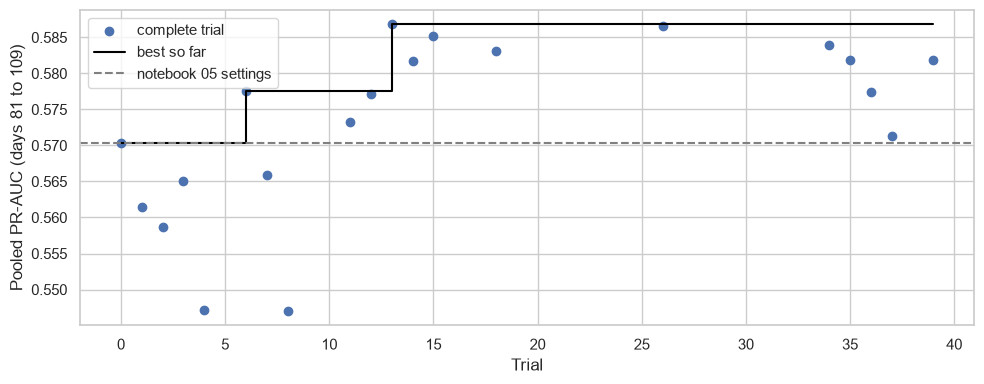

importance of each setting (Optuna fANOVA):


,importance
rsm,0.426
bagging_temperature,0.352
iterations,0.103
depth,0.101
random_strength,0.010
l2_leaf_reg,0.007
class_weights,0.002


tuned settings: {'learning_rate': 0.1, 'iterations': 750, 'depth': 8, 'l2_leaf_reg': 1.5552439007420584, 'random_strength': 0.1325358735488683, 'bagging_temperature': 0.42109136073074666, 'rsm': 0.2810045903691265}


In [15]:
trials = study.trials_dataframe(attrs=("number", "value", "params", "user_attrs", "state"))
new_columns = []
for col in trials.columns:
    new_columns.append(col.removeprefix("params_").removeprefix("user_attrs_"))
trials.columns = new_columns
trials = trials.rename(columns={"value": "PR-AUC"})
complete = trials[trials["state"] == "COMPLETE"].sort_values("PR-AUC", ascending=False)
print("trials:", len(trials), "| complete:", len(complete), "| pruned:", (trials["state"] == "PRUNED").sum())
print("best 10 trials:")
display(complete.drop(columns="state").head(10).round(4))

default_score = trials.loc[trials["number"] == 0, "PR-AUC"].iloc[0]
print(f"first trial (notebook 05 settings): {default_score:.4f} | best trial: {study.best_value:.4f}")

# PR-AUC of each complete trial and the best so far
fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(complete["number"], complete["PR-AUC"], label="complete trial")
best_so_far = complete.sort_values("number").set_index("number")["PR-AUC"].cummax()
ax.step(best_so_far.index, best_so_far, where="post", color="black", label="best so far")
ax.axhline(default_score, color="grey", linestyle="--", label="notebook 05 settings")
ax.set_xlabel("Trial")
ax.set_ylabel("Pooled PR-AUC (days 81 to 109)")
ax.legend()
plt.tight_layout()
plt.show()

# how much each setting changes the score across the complete trials
print("importance of each setting (Optuna fANOVA):")
display(pd.Series(optuna.importance.get_param_importances(study)).rename("importance").round(3).to_frame())

best = study.best_trial
tuned_settings = {"learning_rate": 0.1}
for name, value in best.params.items():
    if name != "class_weights":
        tuned_settings[name] = value
if best.params["class_weights"] != "none":
    tuned_settings["auto_class_weights"] = best.params["class_weights"]
print("tuned settings:", tuned_settings)

**Takeaway: Tuning**
- Tuning raises the pooled PR-AUC from 0.5703 (notebook 05 settings) to 0.5868 (+0.017, trial 13), and trial 13 is higher in all 5 blocks (+0.012 to +0.019) => the gain does not come from one lucky block

- **BUT** this score is the best of 40 trials on the same blocks, so it looks more optimistic than it really is => the real check is in validation rows in Section 6

- Tuned settings: depth 8, 750 trees, `l2_leaf_reg` 1.56, `random_strength` 0.13, `bagging_temperature` 0.42, `rsm` 0.28 and no class weights

- `rsm` and `bagging_temperature` matter the most (Optuna importance 0.43 and 0.35):
    - the best 5 trials all use a low `rsm` (0.20 to 0.31), so each split level only considers a small share of the features. The trials with `rsm` above 0.4 reach at most 0.5776
    - the best 5 trials also use a low `bagging_temperature` (0.33 to 0.65). The mean PR-AUC is 0.5776 below 0.7 vs 0.5629 at 0.7 and above

- The best trials use larger models than notebook 05 (depth 7 to 9 and 700 to 900 trees vs depth 6 and 500 trees)

- Class weights do not help: the 3 complete trials with `SqrtBalanced` reach at most 0.5614 vs 0.5868 without class weights. This fits with M1, where class weights lowered PR-AUC for every family (notebook 05, Section 5)

## 6. Validation Results
We rerun M2 on the validation rows (days 109 to 141) the same way as notebook 05 (Section 9.3): retrained every 7 days on all earlier labelled days (training rows and validation rows that are at least 7 days old), with the encodings refitted before each block. We compare 3 versions:
1. **M2 CatBoost from notebook 05**: all features, notebook 05 settings (loaded from its saved scores)

2. **M2 CatBoost, selected features**: notebook 05 settings, using selected features only => the effect of the feature selection when comparing with M2 CatBoost from notebook 05

3. **M2 Catboost, selected features + tuned settings**: the final M2 CatBoost => the effect of tuning when comparing with M2 Catboost, selected features 

In [16]:
VAL_FIRST_DAY = int(day[is_val].min())
VAL_LAST_DAY = int(day[is_val].max())
labelled_rows = is_train | is_val
val_day = day[is_val]
y_val = y[is_val]


# M2 on the validation rows with the given settings and features, saved so a rerun loads it
def m2_validation_scores(run_name, settings, cols):
    path = RUNS_DIR / f"{run_name}.pkl"
    if path.exists():
        return pd.read_pickle(path).loc[X.index[is_val]].to_numpy()

    start = time.time()
    scores = pd.Series(np.nan, index=X.index[is_val], dtype="float64")

    cat_features = []
    for col in cat_cols:
        if col in cols:
            cat_features.append(col)

    for block_start in range(VAL_FIRST_DAY, VAL_LAST_DAY + 1, FREQUENCY):
        block = is_val & (day >= block_start) & (day < block_start + FREQUENCY)
        fit_rows = labelled_rows & (day < block_start - LABEL_DELAY_DAYS)
        encodings = fit_encodings(labelled_rows & (day < block_start))
        model = CatBoostClassifier(random_seed=SEED, thread_count=-1, verbose=0, allow_writing_files=False, **settings)
        X_fit = apply_encodings(X[fit_rows], encodings)[cols]
        X_block = apply_encodings(X[block], encodings)[cols]
        model.fit(X_fit, y[fit_rows], cat_features=cat_features)
        scores[X.index[block]] = model.predict_proba(X_block)[:, 1]
        del model
    scores.to_pickle(path)
    print(f"{run_name}: {len(cols)} features ({time.time() - start:.0f}s)")
    return scores.to_numpy()


val_scores = {}
notebook05_path = Path("../data/interim/m2_scores_refit/val_m2_CatBoost_freq7_windowall_delay7.pkl")
if notebook05_path.exists():
    val_scores["M2 CatBoost (notebook 05)"] = pd.read_pickle(notebook05_path).loc[X.index[is_val]].to_numpy()
else:
    print("run notebook 05 (Section 9.3) first to get its M2 CatBoost scores")
val_scores["M2 CatBoost, selected features"] = m2_validation_scores(f"val_m2_selected_{len(selected_cols)}", M2_SETTINGS, selected_cols)
val_scores["M2 CatBoost, selected + tuned"] = m2_validation_scores(f"val_m2_tuned_{len(selected_cols)}_trial{best.number}", tuned_settings, selected_cols)

val_m2_selected_115: 115 features (1897s)
val_m2_tuned_115_trial13: 115 features (2278s)


In [17]:
k = 100
metric_cols = ["PR-AUC", "ROC-AUC", "precision", "recall", "F1", f"precision@{k} per day"]


def evaluate(name, scores):
    predictions = (scores >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, predictions, labels=[0, 1]).ravel()

    # precision@k per day: share of fraud among each day's k highest scores, averaged over the days
    daily = pd.DataFrame({"day": val_day, "y": y_val.to_numpy(), "score": scores})
    top_k = daily.sort_values("score", ascending=False, kind="stable").groupby("day").head(k)

    return {"model": name,
            "PR-AUC": average_precision_score(y_val, scores),
            "ROC-AUC": roc_auc_score(y_val, scores),
            "precision": precision_score(y_val, predictions, zero_division=0),
            "recall": recall_score(y_val, predictions, zero_division=0),
            "F1": f1_score(y_val, predictions, zero_division=0),
            f"precision@{k} per day": top_k.groupby("day")["y"].mean().mean(),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}


result_rows = []
for name, scores in val_scores.items():
    result_rows.append(evaluate(name, scores))
results = pd.DataFrame(result_rows).set_index("model")
display(results.round(4))

# PR-AUC per validation week
week = (val_day - VAL_FIRST_DAY) // 7
weekly = []
for name, scores in val_scores.items():
    for w in np.unique(week):
        rows_w = week == w
        weekly.append({"model": name, "week": int(w) + 1, "PR-AUC": average_precision_score(y_val.to_numpy()[rows_w], scores[rows_w])})
display(pd.DataFrame(weekly).pivot_table(index="model", columns="week", values="PR-AUC", sort=False).round(4))

,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN
model,,,,,,,,,,
M2 CatBoost (notebook 05),0.6534,0.9327,0.8432,0.4441,0.5818,0.6309,1645,306,2059,90477
"M2 CatBoost, selected features",0.6524,0.9335,0.8365,0.4517,0.5866,0.6276,1673,327,2031,90456
"M2 CatBoost, selected + tuned",0.6673,0.9374,0.8589,0.4619,0.6008,0.6467,1711,281,1993,90502


week,1,2,3,4,5
model,,,,,
M2 CatBoost (notebook 05),0.6749,0.6480,0.6851,0.6481,0.5733
"M2 CatBoost, selected features",0.6683,0.6327,0.6942,0.6526,0.5830
"M2 CatBoost, selected + tuned",0.6924,0.6394,0.6983,0.6805,0.6082


**Takeaway: Validation Results**
- The final M2 CatBoost (115 selected features + tuned settings) has a validation PR-AUC of 0.667 vs 0.653 for M2 CatBoost from notebook 05 (+0.014), and ROC-AUC goes from 0.933 to 0.937. The gain is above the seed range of 0.006 (M0 CatBoost, notebook 05 Section 5.6) **BUT** this is one seed and that range was not measured on M2

- **The gain comes from the tuning, not from the feature selection**:
    - selected features with the notebook 05 settings: 0.652 vs 0.653 with all 575 features (-0.001, within seed noise). So the selection keeps about the same PR-AUC with 460 fewer features
    - tuned settings on the same features: 0.667 vs 0.652 (+0.015)

- The tuning blocks were too optimistic about the feature selection, as we expected in Section 4.4: +0.017 on the tuning blocks vs -0.001 here => the score that was used to choose the features should not be used to measure their gain. The tuning gain held up better (+0.017 on the tuning blocks vs +0.015 here)

- The gain holds across the weeks: the final model is higher than the selected features with the notebook 05 settings in all 5 weeks (0.004 to 0.028), and higher than notebook 05 in 4 of the 5 weeks (week 2 is lower by 0.009). It is the largest in week 5 (0.608 vs 0.573), which is the weakest week for every version

- It catches more fraud with fewer FP at the 0.5 threshold: 1,711 frauds caught and 281 false alerts vs 1,645 and 306 in notebook 05, so both precision (0.859 vs 0.843) and recall (0.462 vs 0.444) increase. Precision@100 per day goes from 0.631 to 0.647

Note: the actual threshold will be chosen later after M4

M2 CatBoost with these features and settings is the model we carry forward => M3 has to beat a validation PR-AUC of 0.667